# DSCI 552 — Homework 6

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative path `../data/aps_failure/`, so the notebook should be run from the `notebook/` folder. SMOTE is applied to the **full** training set (no downsampling).

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 552
N_JOBS = -1

## 1. Tree-Based Methods

### (a) APS Failure data

The data was downloaded from the UCI repository and is stored in `../data/aps_failure/`. Each CSV file starts with a 20-line license header, missing values are coded as `na`, and the label is `class` (`neg` / `pos`). The positive class is a failure of a specific component of the Air Pressure System (APS); `pos` is coded as 1.

In [2]:
DATA = Path("../data/aps_failure")
train = pd.read_csv(DATA / "aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv(DATA / "aps_failure_test_set.csv", skiprows=20, na_values="na")

y_train = (train.pop("class") == "pos").astype(int).to_numpy()
y_test = (test.pop("class") == "pos").astype(int).to_numpy()
features = train.columns.tolist()

print("training set:", train.shape, " test set:", test.shape)
print("features:", len(features))
train.head()

training set: (60000, 170)  test set: (16000, 170)
features: 170


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,ap_000,...,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,0.0,0.0,4933296.0,3655166.0,1766008.0,...,0.0,0.0,202710.0,37928.0,14745580.0,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,0.0,0.0,2560898.0,2127150.0,1084598.0,...,0.0,0.0,103330.0,16254.0,4510080.0,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,0.0,0.0,2371990.0,2173634.0,300796.0,...,0.0,0.0,65772.0,10534.0,300240.0,48028.0,0.0,0.0,0.0,0.0,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,0.0,0.0,2668.0,0.0,0.0,0.0,642.0,3894.0,10184.0,7554.0,10764.0,...,2014.0,370.0,48.0,18.0,15740.0,1822.0,20174.0,44.0,0.0,0.0,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,4588.0,0.0,1974038.0,0.0,226.0,0.0,0.0,0.0,3230626.0,2618878.0,1058136.0,...,0.0,0.0,149474.0,35154.0,457040.0,80482.0,98334.0,27588.0,0.0,0.0,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data preparation

#### i. Missing values

Common techniques for data with missing values:

1. **Deletion** — listwise deletion (drop every row with a missing value) or dropping features that are mostly missing. Simple, but it throws data away and can bias the sample if values are not missing completely at random.
2. **Simple statistical imputation** — replace a missing value by the mean, median or mode of the feature. Fast; the median is robust to skewed features and outliers. It shrinks the variance of the feature and ignores relations between features.
3. **Missing-value indicators** — add a binary column "value was missing", usually together with 2., so that the model can use the missingness pattern itself.
4. **Model-based imputation** — predict the missing value from the other features: k-nearest-neighbour imputation, regression imputation, MICE / iterative imputation (chained regressions), EM for a parametric model, matrix factorization.
5. **Multiple imputation** — draw several imputed data sets, fit the model on each and pool the results, so that the uncertainty of the imputation is kept.
6. **Methods that handle missing values internally** — CART surrogate splits, or XGBoost's learned default direction at each split.

Deletion is not an option here: the cell below shows that 59,409 of the 60,000 training rows have at least one missing value, and that some features are missing in more than 80% of the rows.

I use **median imputation** (technique 2): the features are counts and histogram bins with very long right tails, so the median is a much better "typical value" than the mean. Following the footnote of the assignment, the training set is imputed with the medians of the training set, and the test set is imputed with the medians of the test set (the model does not use training statistics to fill in test data).

In [3]:
miss = train.isna().mean().sort_values(ascending=False)
print("rows with at least one missing value: %d of %d" % (train.isna().any(axis=1).sum(), len(train)))
print("features with at least one missing value: %d of %d" % ((miss > 0).sum(), len(features)))
print("features missing in more than 50%% of rows: %d" % (miss > 0.5).sum())
print("\nfeatures with the largest fraction of missing values (training set):")
print(miss.head(10).round(3).to_string())

rows with at least one missing value: 59409 of 60000
features with at least one missing value: 169 of 170
features missing in more than 50% of rows: 8

features with the largest fraction of missing values (training set):
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772
bn_000    0.733
bm_000    0.659
bl_000    0.455
bk_000    0.384


In [4]:
X_train = train.fillna(train.median())
X_test = test.fillna(test.median())
print("missing values left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

missing values left: 0 0


#### ii. Coefficient of variation

$CV = s / m$, with $s$ the sample standard deviation and $m$ the sample mean of each feature, computed on the imputed training set.

In [5]:
cv = (X_train.std(ddof=1) / X_train.mean()).rename("CV")
cv_table = pd.DataFrame({"mean": X_train.mean(), "std": X_train.std(ddof=1), "CV": cv}).sort_values("CV", ascending=False)
print(cv_table["CV"].describe().round(3).to_string())
print("\nfeatures with CV = 0 (constant):", cv_table.index[cv_table["CV"] == 0].tolist())
cv_table.round(4)

count    170.000
mean      20.154
std       41.303
min        0.000
25%        2.600
50%        4.881
75%       17.232
max      244.888

features with CV = 0 (constant): ['cd_000']


,mean,std,CV
cf_000,1.431075e+05,3.504525e+07,244.8875
co_000,1.433300e+05,3.504525e+07,244.5074
ad_000,1.434383e+05,3.504525e+07,244.3228
cs_009,7.705097e+02,1.833278e+05,237.9306
dh_000,4.392641e+03,5.412441e+05,123.2161
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.7924
bp_000,3.420739e+05,2.577156e+05,0.7534
bq_000,3.573117e+05,2.567407e+05,0.7185
br_000,3.713041e+05,2.558701e+05,0.6891


In [6]:
with pd.option_context("display.max_rows", 200):
    display(cv_table[["CV"]].round(3).T)

,cf_000,co_000,ad_000,cs_009,dh_000,dj_000,ag_000,as_000,ay_009,ak_000,az_009,ch_000,au_000,cr_000,ay_001,df_000,dz_000,ef_000,cs_008,aj_000,eg_000,dl_000,ay_002,dg_000,ay_000,...,ah_000,ac_000,bg_000,ce_000,ao_000,an_000,dt_000,do_000,cs_006,dp_000,cs_000,cv_000,dc_000,bs_000,ca_000,cb_000,bl_000,bm_000,bn_000,bk_000,bo_000,bp_000,bq_000,br_000,cd_000
CV,244.888,244.507,244.323,237.931,123.216,117.494,92.918,87.332,84.734,80.425,77.839,77.454,68.883,58.078,52.825,52.293,51.332,49.367,48.102,44.266,42.482,39.739,39.249,38.486,37.428,...,2.312,2.31,2.309,2.271,2.271,2.25,2.192,2.166,2.143,2.022,1.881,1.837,1.725,1.051,0.932,0.909,0.871,0.849,0.836,0.82,0.792,0.753,0.719,0.689,0.0


**Discussion.** The CVs are large: the median feature has CV ≈ 4.9 and the largest is ≈ 245, because most features are counts or histogram bins that are 0 for most trucks and very large for a few. `cd_000` has the same value for every truck (CV = 0), so it carries no information; it is kept in the data because tree-based models simply never split on it.

#### iii. Correlation matrix

Pearson correlation matrix of the 170 features (imputed training set). `cd_000` is constant, so its correlations are undefined (blank row/column).

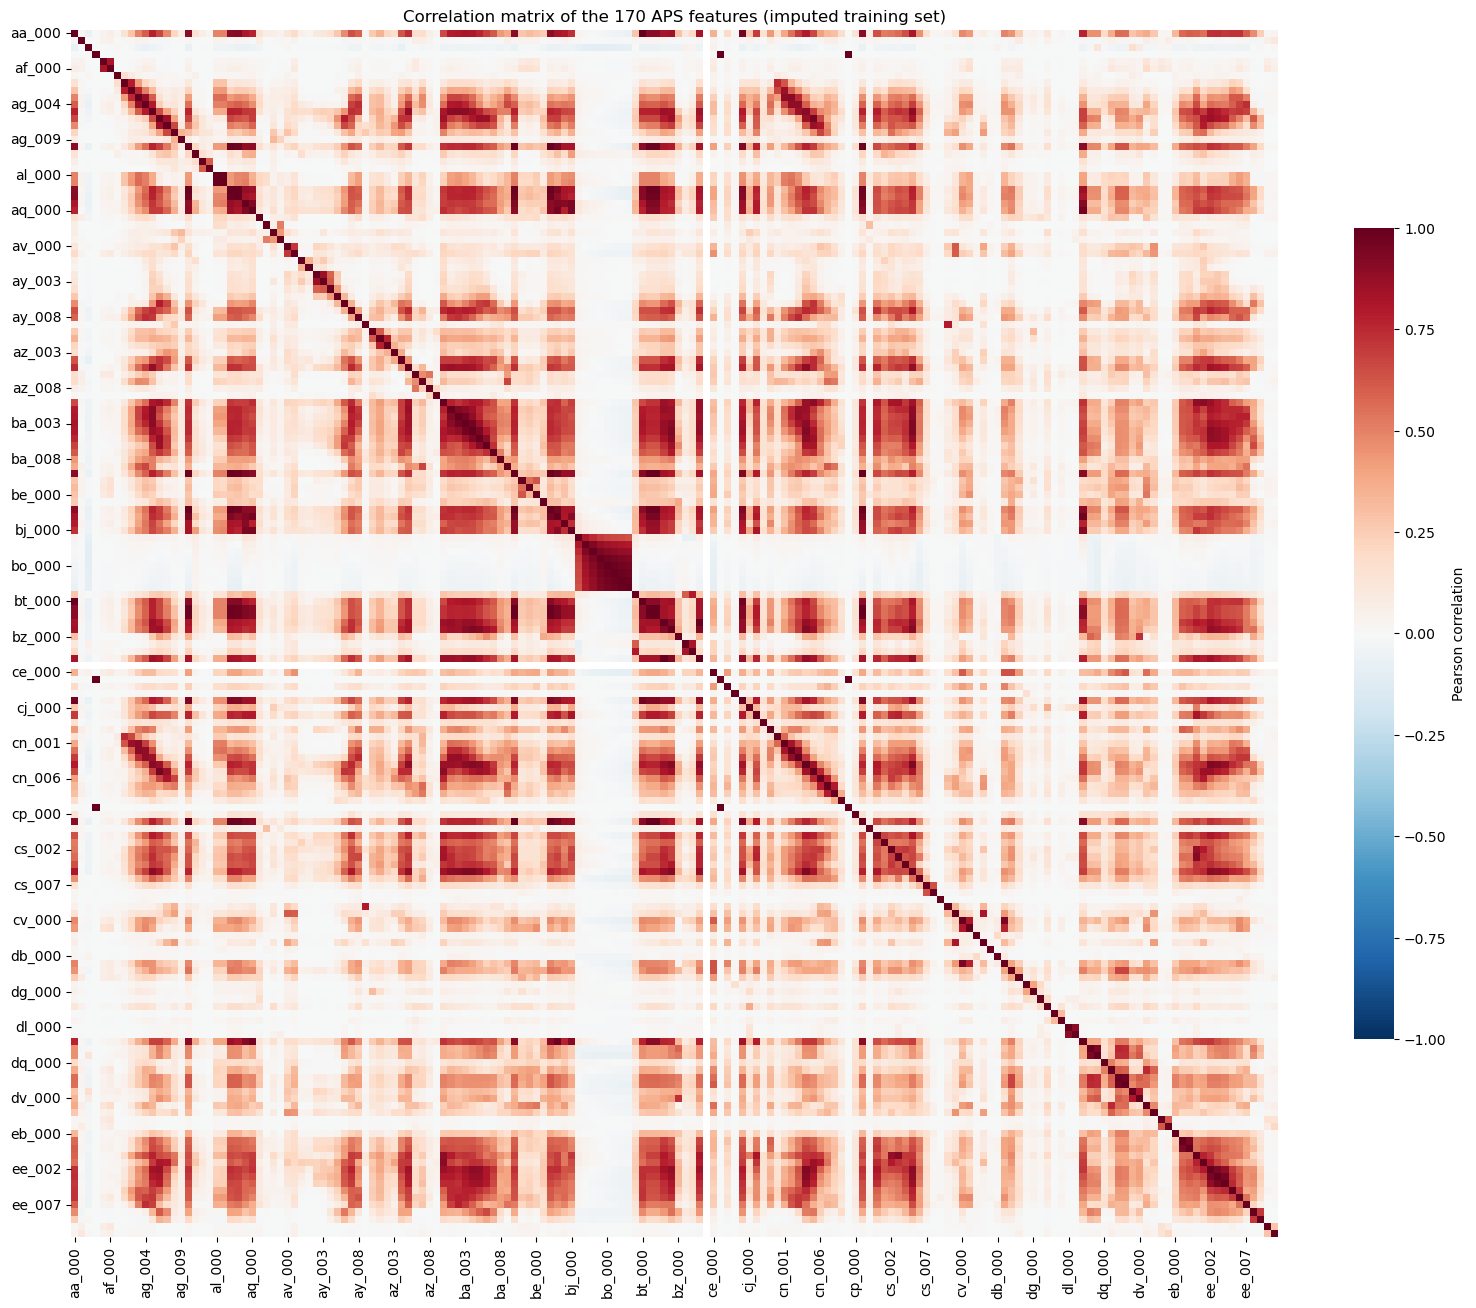

feature pairs: 14196
pairs with |r| > 0.9: 130,  |r| > 0.7: 772

most correlated pairs:
bv_000  cq_000    1.0000
bu_000  cq_000    1.0000
        bv_000    1.0000
cf_000  co_000    1.0000
ad_000  cf_000    1.0000
        co_000    1.0000
aa_000  bt_000    0.9988
ah_000  bg_000    0.9977
bb_000  bv_000    0.9963
        bu_000    0.9963


In [7]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=5, yticklabels=5,
            cbar_kws={"shrink": 0.6, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation matrix of the 170 APS features (imputed training set)")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("feature pairs: %d" % len(upper))
print("pairs with |r| > 0.9: %d,  |r| > 0.7: %d" % ((upper.abs() > 0.9).sum(), (upper.abs() > 0.7).sum()))
print("\nmost correlated pairs:")
print(upper.abs().sort_values(ascending=False).head(10).round(4).to_string())

**Discussion.** Most of the matrix is close to 0, but there are clear blocks of strongly positively correlated features: 130 of the 14,196 pairs have |r| > 0.9 and 772 have |r| > 0.7. Several groups are essentially copies of each other (e.g. `bu_000`, `bv_000`, `cq_000`; `ad_000`, `cf_000`, `co_000`, all with r ≈ 1.0), and the histogram bins of the same physical quantity (e.g. `ag_00*`, `ay_00*`, `cs_00*`) are correlated with their neighbouring bins. Strong negative correlations are almost absent. This redundancy is one reason to prefer tree ensembles with random feature subsets over, for example, an unregularized logistic regression.

#### iv. The ⌊√170⌋ = 13 features with the highest CV

The features are highly skewed (many zeros and a few huge values), so both plots use $\log_{10}(1 + x)$ to make the bulk of the data visible. For the scatter-plot matrix (in the style of ISLR Fig. 3.6 / the `Auto` pairs plot), all 1,000 positive trucks and a random sample of 5,000 negative trucks are plotted, so that the positive class is not hidden under 59,000 negative points; the box plots use the whole training set.

13 features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


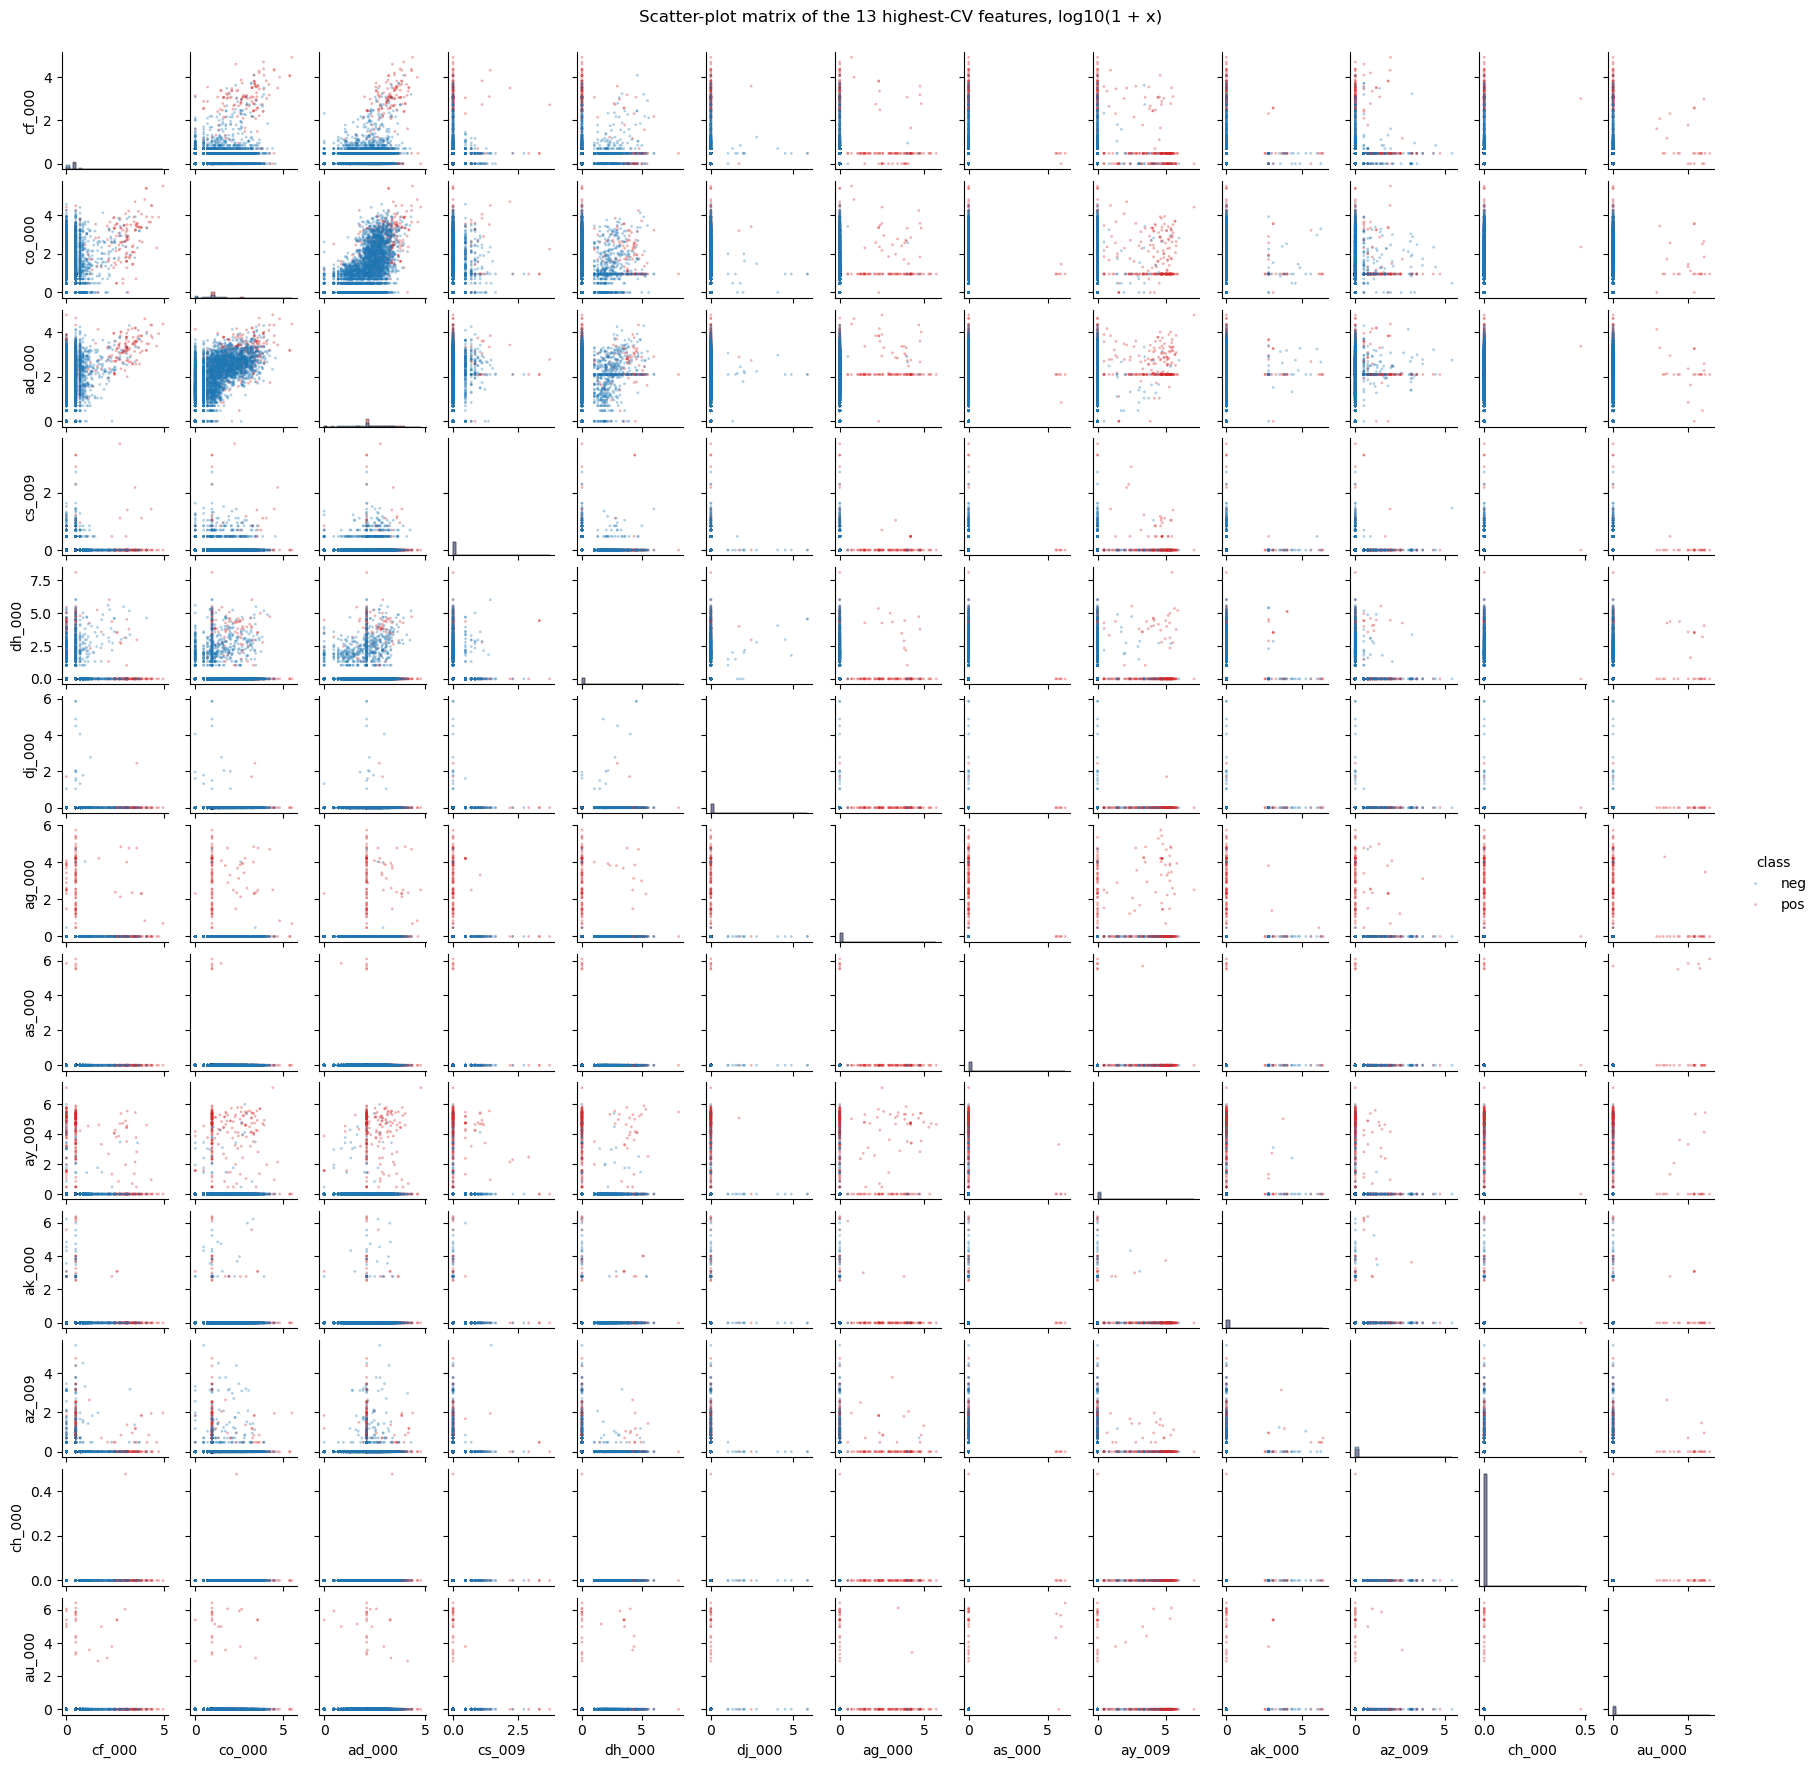

In [8]:
k = int(np.floor(np.sqrt(170)))
top = cv_table.index[:k].tolist()
print(k, "features:", top)

rng = np.random.default_rng(SEED)
idx = np.r_[np.flatnonzero(y_train == 1), rng.choice(np.flatnonzero(y_train == 0), 5000, replace=False)]
viz = np.log10(1 + X_train.loc[idx, top].clip(lower=0))
viz["class"] = np.where(y_train[idx] == 1, "pos", "neg")

g = sns.pairplot(viz, vars=top, hue="class", hue_order=["neg", "pos"], palette={"neg": "tab:blue", "pos": "tab:red"},
                 diag_kind="hist", corner=False, height=1.35,
                 plot_kws={"s": 4, "alpha": 0.35, "linewidth": 0}, diag_kws={"bins": 30, "common_norm": False, "stat": "density"})
g.figure.suptitle("Scatter-plot matrix of the 13 highest-CV features, log10(1 + x)", y=1.01)
plt.show()

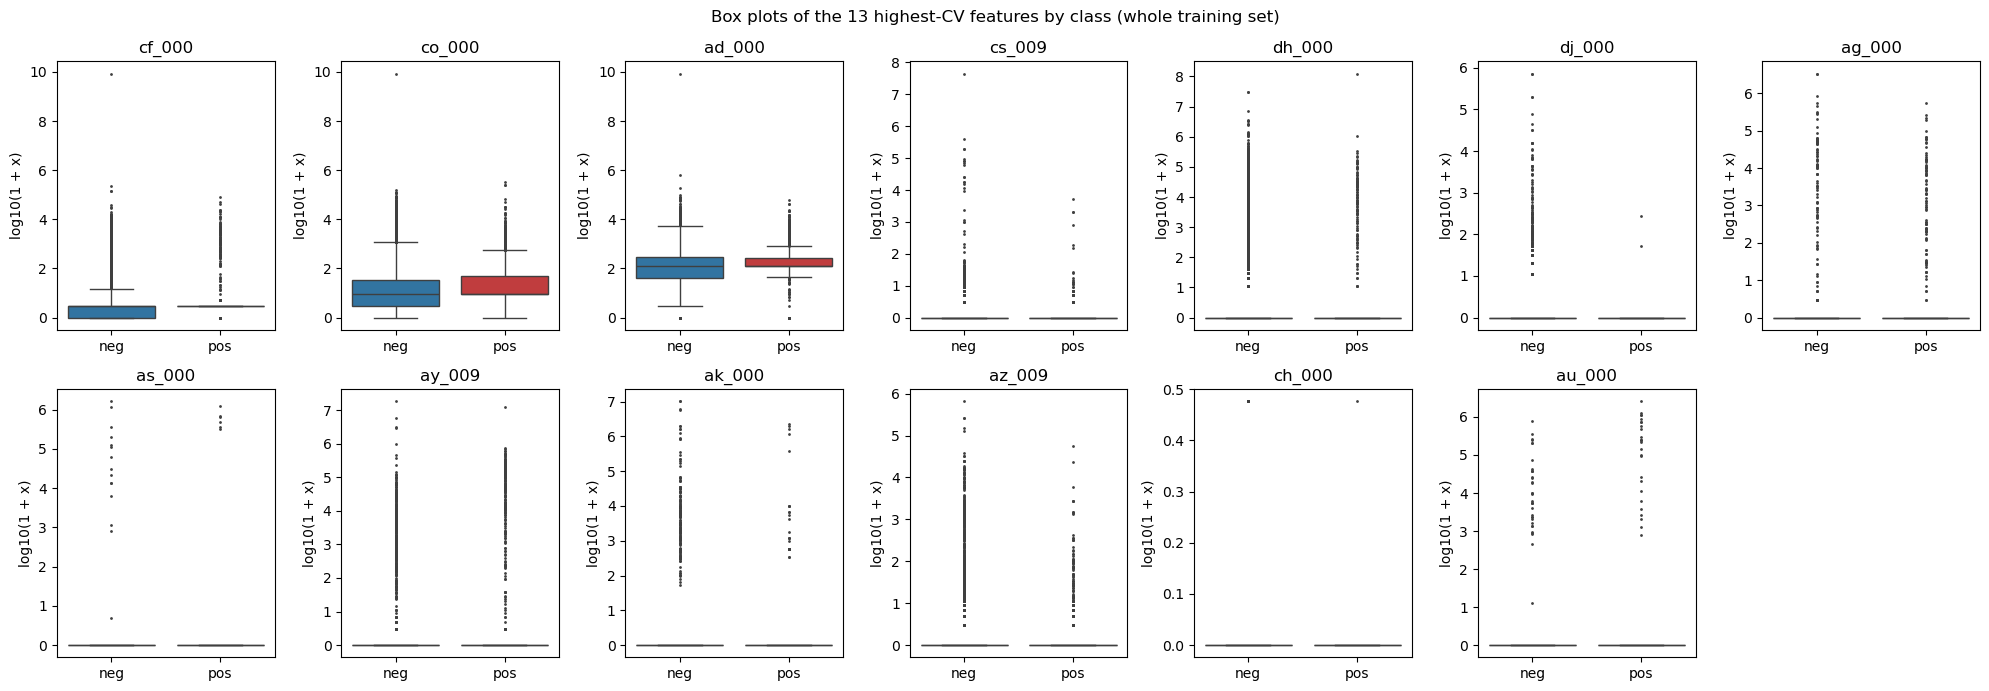

,median (neg),median (pos)
cf_000,2.0,2.0
co_000,8.0,8.0
ad_000,126.0,126.0
cs_009,0.0,0.0
dh_000,0.0,0.0
dj_000,0.0,0.0
ag_000,0.0,0.0
as_000,0.0,0.0
ay_009,0.0,0.0
ak_000,0.0,0.0


In [9]:
box = np.log10(1 + X_train[top].clip(lower=0)).assign(**{"class": np.where(y_train == 1, "pos", "neg")})
fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for ax, f in zip(axes.ravel(), top):
    sns.boxplot(data=box, x="class", y=f, order=["neg", "pos"], hue="class", hue_order=["neg", "pos"],
                palette={"neg": "tab:blue", "pos": "tab:red"}, fliersize=1, legend=False, ax=ax)
    ax.set_title(f)
    ax.set_xlabel("")
    ax.set_ylabel("log10(1 + x)")
axes.ravel()[-1].axis("off")
fig.suptitle("Box plots of the 13 highest-CV features by class (whole training set)")
plt.tight_layout()
plt.show()

med = X_train[top].groupby(y_train).median().T
med.columns = ["median (neg)", "median (pos)"]
med

**Discussion.** No, the plots do not let us draw reliable conclusions about the significance of these features. For 10 of the 13 features, the median is 0 in both classes, and the boxes collapse to a line at 0. The classes differ only in how often and how large the rare non-zero values are, and that is hard to judge from overplotted points. The scatter plots show the positive points spread over the same region as the negative points for most pairs. The only visible shifts are for `ad_000`, `co_000` and `cf_000` (all three are almost the same feature, r ≈ 1), where positive trucks have a narrower distribution and slightly larger typical values, and for `ag_000`, `ay_009` and `au_000`, where large values are relatively more frequent in the positive class. A high CV only means that a feature is spread out relative to its mean, not that it separates the classes. Significance has to be judged with a model or a test, not from these plots.

#### v. Class balance

In [10]:
counts = pd.DataFrame({
    "training": pd.Series(y_train).value_counts().sort_index().values,
    "test": pd.Series(y_test).value_counts().sort_index().values,
}, index=["negative (0)", "positive (1)"])
counts.loc["positive fraction"] = (counts.loc["positive (1)"] / counts.iloc[:2].sum()).round(4)
counts

,training,test
negative (0),59000.0000,15625.0000
positive (1),1000.0000,375.0000
positive fraction,0.0167,0.0234


**Discussion.** The training set has 59,000 negative and 1,000 positive trucks (1.67% positive), and the test set has 15,625 negative and 375 positive (2.34%). The data is **severely imbalanced**: a classifier that always predicts "negative" already has a training error of only 1.67% and a test error of 2.34%.

### (c) Random forest without compensation for class imbalance

A random forest with 300 trees (`max_features = √p`, fully grown trees, default settings otherwise) is trained on the imputed training set. Predictions use the default threshold 0.5 on the forest's probability. For the training and test sets the confusion matrix, ROC curve, AUC and misclassification rate are reported. The out-of-bag (OOB) error estimate is `1 - oob_score_`.

As an extra column, the table also shows the challenge cost of the data donors, $\text{cost} = 10 \cdot FP + 500 \cdot FN$ (a missed APS failure is 50 times as expensive as an unnecessary check).

In [11]:
results = {}


def evaluate(name, model, extra=None):
    # Confusion matrix, misclassification, AUC and ROC curve on the training and test sets.
    rows, rocs = {}, {}
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        p = model.predict_proba(X)[:, 1]
        yhat = (p >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
        rows[split] = {"misclassification": 1 - accuracy_score(y, yhat), "AUC": roc_auc_score(y, p),
                       "TN": tn, "FP": fp, "FN": fn, "TP": tp, "cost": 10 * fp + 500 * fn}
        rocs[split] = roc_curve(y, p)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for ax, split in zip(axes[:2], ["train", "test"]):
        r = rows[split]
        ConfusionMatrixDisplay(np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]]),
                               display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{name}: {split} confusion matrix")
    for split, ls in [("train", "--"), ("test", "-")]:
        fpr, tpr, _ = rocs[split]
        axes[2].plot(fpr, tpr, ls, label=f"{split} (AUC = {rows[split]['AUC']:.4f})")
    axes[2].plot([0, 1], [0, 1], ":", color="grey")
    axes[2].set_xlabel("false positive rate")
    axes[2].set_ylabel("true positive rate")
    axes[2].set_title(f"{name}: ROC")
    axes[2].legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    table = pd.DataFrame(rows).T
    print(table.to_string(formatters={"misclassification": "{:.5f}".format, "AUC": "{:.5f}".format}))
    results[name] = {"train error": rows["train"]["misclassification"], "test error": rows["test"]["misclassification"],
                     "train AUC": rows["train"]["AUC"], "test AUC": rows["test"]["AUC"],
                     "test FP": rows["test"]["FP"], "test FN": rows["test"]["FN"], "test cost": rows["test"]["cost"],
                     **(extra or {})}
    return table

fit time: 51.2 s


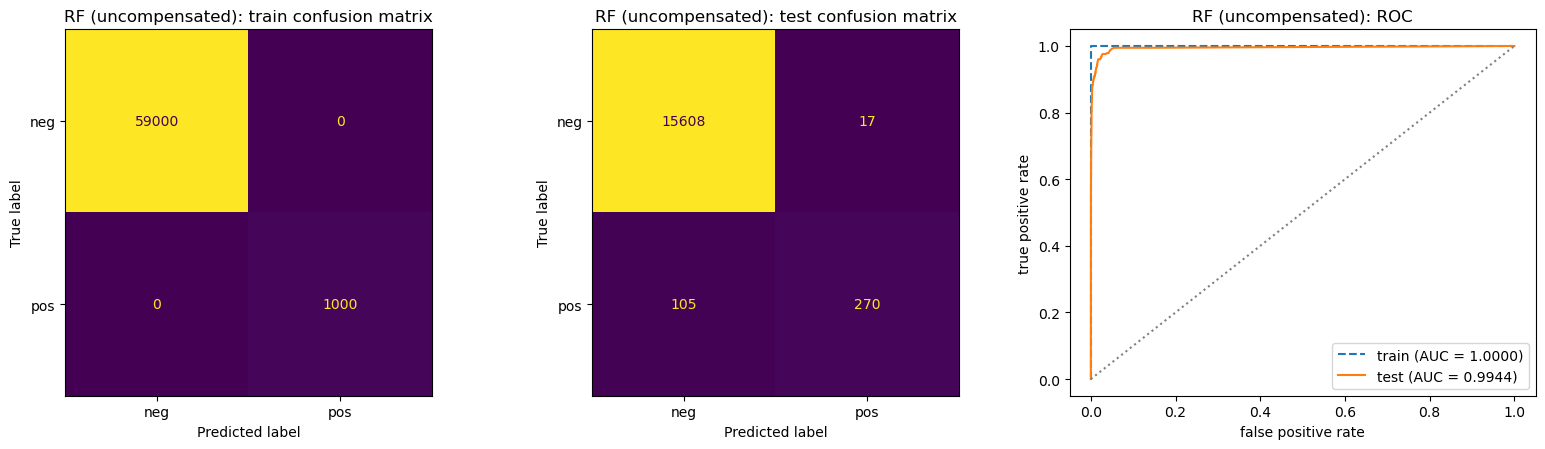

      misclassification     AUC       TN    FP     FN      TP     cost
train           0.00000 1.00000  59000.0   0.0    0.0  1000.0      0.0
test            0.00762 0.99445  15608.0  17.0  105.0   270.0  52670.0

OOB error estimate: 0.00575   test error: 0.00762


In [12]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=N_JOBS, random_state=SEED)
rf.fit(X_train, y_train)
print("fit time: %.1f s" % (time.time() - t0))

oob_err = 1 - rf.oob_score_
rf_table = evaluate("RF (uncompensated)", rf, {"OOB / CV error": oob_err})
print("\nOOB error estimate: %.5f   test error: %.5f" % (oob_err, rf_table.loc["test", "misclassification"]))

**Discussion.** The forest fits the training set perfectly (no training errors, AUC = 1), as expected for fully grown trees. On the test set the misclassification rate is 0.76% and the AUC is 0.994. The **OOB error estimate (0.575%) is a little lower than the test error (0.762%)**. Part of the gap comes from the larger fraction of positives in the test set (2.34% vs. 1.67%): almost all of the errors are on positive trucks, so a test set with more positives has a higher error. The confusion matrix shows the effect of the imbalance: only 17 false positives, but 105 of the 375 failing trucks (28%) are missed. Because a missed failure costs 50 times as much as an unnecessary check, this "accurate" model has a high cost (52,670).

### (d) Compensating for class imbalance in random forests

How class imbalance is handled in random forests (Chen, Liaw and Breiman, *Using Random Forest to Learn Imbalanced Data*, 2004, and later work):

1. **Weighted random forest (cost-sensitive learning)** — give the minority class a larger weight, e.g. inversely proportional to the class frequency. The weights enter the Gini criterion when splits are chosen and the weighted vote in the terminal nodes. In scikit-learn: `class_weight="balanced"` or `"balanced_subsample"` (weights recomputed on every bootstrap sample).
2. **Balanced random forest (sampling)** — for each tree, draw a bootstrap sample of the minority class and a sample of the same size from the majority class (down-sampling), and grow the tree on this balanced sample. In `imbalanced-learn`: `BalancedRandomForestClassifier`.
3. **Re-sampling the whole training set** before training (random over-/under-sampling, SMOTE), or **moving the decision threshold** away from 0.5 (or using a stratified / cut-off vote).

Below, methods 1 and 2 are both used, with the same 300 trees and seed as in (c). The weighted forest has an OOB estimate from scikit-learn. For the balanced forest, each tree is grown on a bootstrap sample of the training set that is then down-sampled to balance the classes (`bootstrap=True, replacement=False, sampling_strategy="auto"`), so a training point that is not in the bootstrap sample is out-of-bag for that tree, and `oob_score_` is available.

fit time: 33.0 s


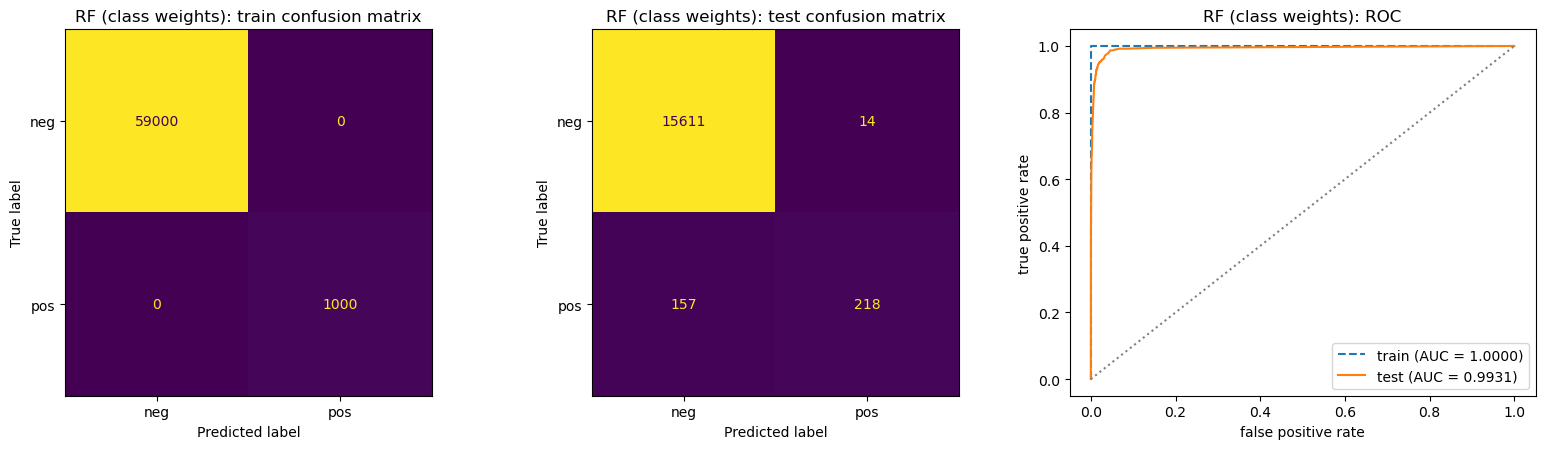

      misclassification     AUC       TN    FP     FN      TP     cost
train           0.00000 1.00000  59000.0   0.0    0.0  1000.0      0.0
test            0.01069 0.99308  15611.0  14.0  157.0   218.0  78640.0

OOB error estimate: 0.00767   test error: 0.01069


In [13]:
t0 = time.time()
rf_w = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", oob_score=True,
                              n_jobs=N_JOBS, random_state=SEED)
rf_w.fit(X_train, y_train)
print("fit time: %.1f s" % (time.time() - t0))
oob_w = 1 - rf_w.oob_score_
rf_w_table = evaluate("RF (class weights)", rf_w, {"OOB / CV error": oob_w})
print("\nOOB error estimate: %.5f   test error: %.5f" % (oob_w, rf_w_table.loc["test", "misclassification"]))

D:\Anaconda\Lib\site-packages\imblearn\ensemble\_forest.py:887: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


fit time: 4.2 s


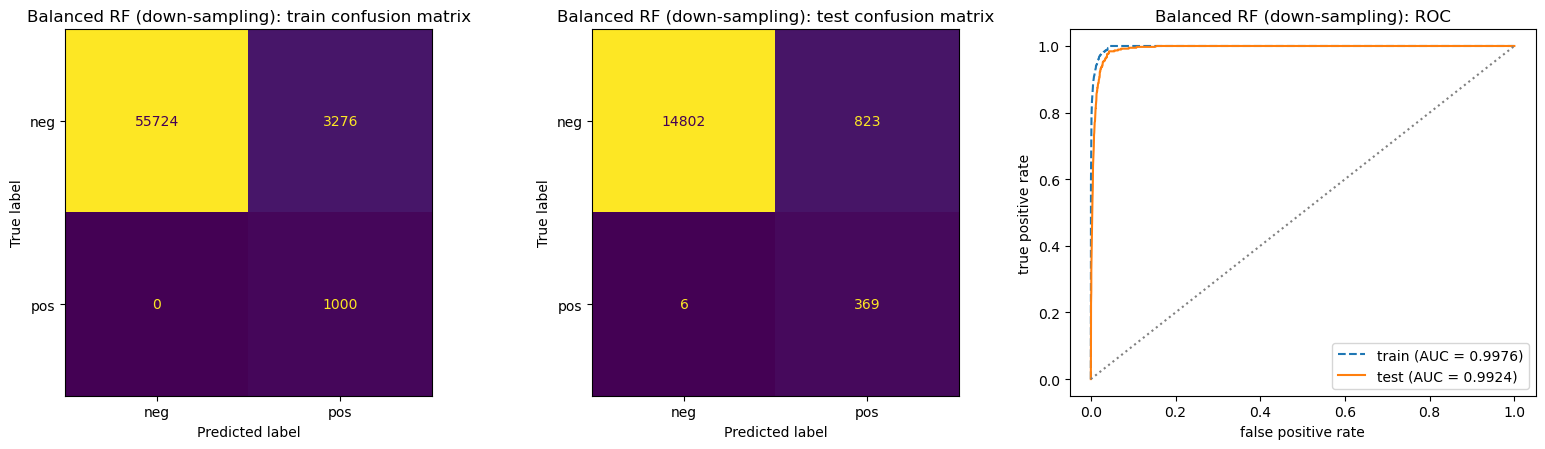

      misclassification     AUC       TN      FP   FN      TP     cost
train           0.05460 0.99759  55724.0  3276.0  0.0  1000.0  32760.0
test            0.05181 0.99240  14802.0   823.0  6.0   369.0  11230.0

OOB error estimate: 0.05063   test error: 0.05181


In [14]:
t0 = time.time()
brf = BalancedRandomForestClassifier(n_estimators=300, sampling_strategy="auto", replacement=False, bootstrap=True,
                                     oob_score=True, n_jobs=N_JOBS, random_state=SEED)
brf.fit(X_train, y_train)
print("fit time: %.1f s" % (time.time() - t0))
oob_b = 1 - brf.oob_score_
brf_table = evaluate("Balanced RF (down-sampling)", brf, {"OOB / CV error": oob_b})
print("\nOOB error estimate: %.5f   test error: %.5f" % (oob_b, brf_table.loc["test", "misclassification"]))

In [15]:
pd.DataFrame(results).T[["OOB / CV error", "train error", "test error", "train AUC", "test AUC", "test FP", "test FN", "test cost"]]

,OOB / CV error,train error,test error,train AUC,test AUC,test FP,test FN,test cost
RF (uncompensated),0.005750,0.0000,0.007625,1.000000,0.994446,17.0,105.0,52670.0
RF (class weights),0.007667,0.0000,0.010687,1.000000,0.993082,14.0,157.0,78640.0
Balanced RF (down-sampling),0.050633,0.0546,0.051813,0.997593,0.992404,823.0,6.0,11230.0


**Discussion: comparison with (c).**

- **Class weights** barely change the forest and even make it slightly worse (test error 1.07%, AUC 0.993, 157 missed failures). With fully grown trees, every leaf is pure, so the weights change the choice of splits a little but not the votes of the leaves, and the predicted probabilities stay close to those in (c). Weighting needs shallower trees (e.g. `min_samples_leaf`) or a different threshold to have an effect.
- **The balanced random forest** changes the trade-off completely. Each tree is grown on about 1,000 positive and 1,000 negative trucks, so the forest's probabilities are no longer biased towards the majority class. The misclassification rate rises (5.2% test, 5.1% OOB), because 823 negative test trucks are flagged, but only **6 of the 375 failures are missed** (recall 98.4% vs. 72% in (c)). The test AUC is 0.992, about the same as in (c). This shows that the ranking of the trucks barely changes; what changes is where the decision threshold effectively lies. With the challenge cost, the balanced forest is much better (11,230 vs. 52,670).
- The OOB estimates are again close to the test errors in all three cases. (The warning means that a few training points happened to be in the bootstrap sample of every tree; they are left out of the OOB estimate.)

Overall: compensating for the imbalance does **not** reduce the misclassification rate, which is dominated by the majority class. It greatly increases the detection of the rare class, and that is what matters in this application.

### (e) XGBoost with L1 regularization (model trees)

**How this maps onto XGBoost.** `XGBClassifier` with `objective="binary:logistic"` fits an additive model $f(x) = \sum_t f_t(x)$ of regression trees on the log-odds scale, i.e. a logistic regression whose "features" are the trees, by Newton boosting of the logistic loss. The parameter `reg_alpha` = α adds the L1 penalty $\alpha \sum_j |w_j|$ on the leaf values $w_j$ of every tree to the objective: it soft-thresholds the leaf values, sets small ones exactly to zero and prunes splits whose gain does not pay for the penalty. This is the L1-penalized logistic model at each node that the assignment asks for. (XGBoost does not literally fit a separate linear logistic regression inside every node; `booster="gblinear"` would give a single L1-penalized logistic regression without any tree.)

α is chosen by **5-fold stratified cross-validation** on the training set over α ∈ {0, 0.01, 0.1, 1, 10, 30}, with misclassification error as the criterion (AUC is recorded too). The other hyper-parameters are fixed: 300 trees, learning rate 0.1, maximum depth 6, histogram tree method. No compensation for class imbalance is used. After choosing α, the model is refitted on the whole training set, and its CV error is compared with the test error.

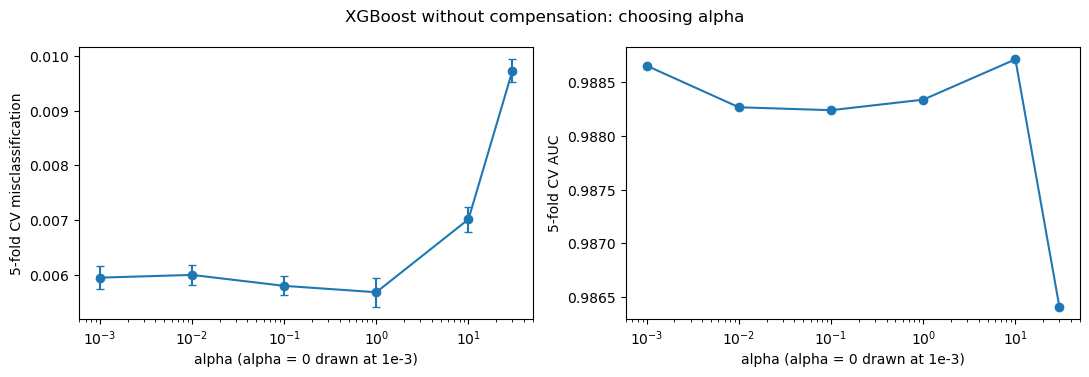

,CV error,CV error SE,CV AUC,seconds
alpha,,,,
0.00,0.00595,0.00021,0.98865,32.57598
0.01,0.00600,0.00018,0.98827,32.46347
0.10,0.00580,0.00017,0.98824,34.20486
1.00,0.00568,0.00027,0.98834,34.58329
10.00,0.00702,0.00023,0.98871,21.47385
30.00,0.00973,0.00021,0.98641,16.11957


In [16]:
ALPHAS = [0, 0.01, 0.1, 1, 10, 30]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_xgb(alpha):
    return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, reg_alpha=alpha, reg_lambda=0,
                         objective="binary:logistic", tree_method="hist", eval_metric="logloss",
                         n_jobs=N_JOBS, random_state=SEED)


def cv_over_alpha(make_model, X, y):
    rows = []
    for a in ALPHAS:
        t0 = time.time()
        s = cross_validate(make_model(a), X, y, cv=skf, scoring=["accuracy", "roc_auc"], n_jobs=1)
        rows.append({"alpha": a, "CV error": 1 - s["test_accuracy"].mean(), "CV error SE": s["test_accuracy"].std(ddof=1) / np.sqrt(5),
                     "CV AUC": s["test_roc_auc"].mean(), "seconds": time.time() - t0})
    return pd.DataFrame(rows).set_index("alpha")


def plot_cv(table, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    x = [a if a > 0 else 1e-3 for a in table.index]
    ax[0].errorbar(x, table["CV error"], yerr=table["CV error SE"], marker="o", capsize=3)
    ax[1].plot(x, table["CV AUC"], marker="o")
    for a_, lab in zip(ax, ["5-fold CV misclassification", "5-fold CV AUC"]):
        a_.set_xscale("log")
        a_.set_xlabel("alpha (alpha = 0 drawn at 1e-3)")
        a_.set_ylabel(lab)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


cv_xgb = cv_over_alpha(make_xgb, X_train, y_train)
plot_cv(cv_xgb, "XGBoost without compensation: choosing alpha")
cv_xgb.round(5)

alpha chosen by 5-fold CV: 1.0


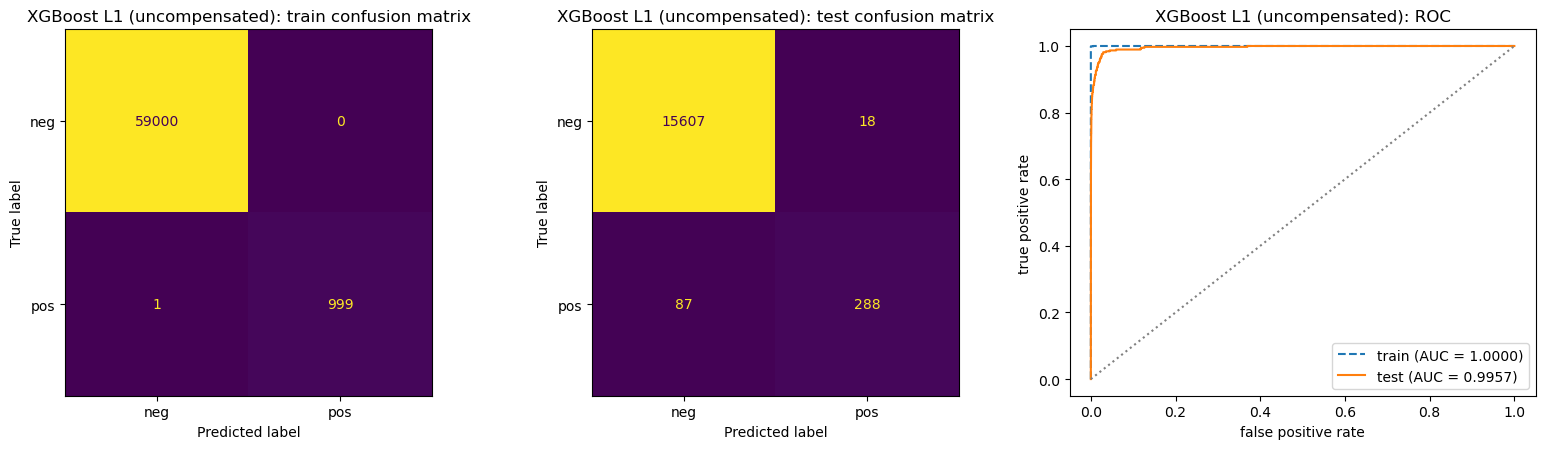

      misclassification     AUC       TN    FP    FN     TP     cost
train           0.00002 0.99999  59000.0   0.0   1.0  999.0    500.0
test            0.00656 0.99570  15607.0  18.0  87.0  288.0  43680.0

5-fold CV error estimate: 0.00568   test error: 0.00656


In [17]:
alpha_xgb = cv_xgb["CV error"].idxmin()
print("alpha chosen by 5-fold CV:", alpha_xgb)
xgb = make_xgb(alpha_xgb).fit(X_train, y_train)
xgb_table = evaluate("XGBoost L1 (uncompensated)", xgb, {"OOB / CV error": cv_xgb.loc[alpha_xgb, "CV error"]})
print("\n5-fold CV error estimate: %.5f   test error: %.5f" % (cv_xgb.loc[alpha_xgb, "CV error"], xgb_table.loc["test", "misclassification"]))

**Discussion.** The CV error is flat for α between 0 and 1 (0.57–0.60%, differences within one standard error), and rises for α = 10 and α = 30, where the L1 penalty shrinks the leaf values so much that the 300 trees underfit. CV chooses **α = 1**. The **5-fold CV error estimate (0.568%) is slightly lower than the test error (0.656%)**, for the same reason as the OOB estimate in (c): the test set contains a larger share of positives, and most errors are positives. Compared with the uncompensated random forest, XGBoost has a lower test error (0.656% vs. 0.762%) and a higher test AUC (0.9957 vs. 0.9944), and misses fewer failures (87 vs. 105), but it still misses 23% of them. It also fits the training set almost perfectly (one training error), so the training error says nothing about generalization.

### (f) SMOTE + XGBoost

SMOTE creates synthetic minority points on the line segments between a positive training point and one of its k = 5 nearest positive neighbours, until the two classes have the same size. It is applied to the **whole** training set (59,000 negatives, so the 1,000 positives are over-sampled to 59,000 — 118,000 rows in total).

**The right and the wrong way of cross-validation.** The synthetic points are interpolations of real positive points. If SMOTE is applied to the whole training set *before* splitting it into folds, synthetic copies of a validation point's neighbours (built partly from the validation point itself) end up in the training folds, and the validation folds also contain synthetic points instead of the real class distribution. The CV error is then far too optimistic. The right way is to put SMOTE *inside* the cross-validation loop: in every fold, SMOTE is fitted on the 4 training folds only, and the model is evaluated on the untouched held-out fold with its real class ratio. This is done with an `imblearn` `Pipeline`, whose sampler is only applied during `fit`.

α is again chosen over the same grid by 5-fold CV (the right way); the final model is SMOTE on the whole training set + XGBoost with the chosen α. The test set is never re-sampled.

D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


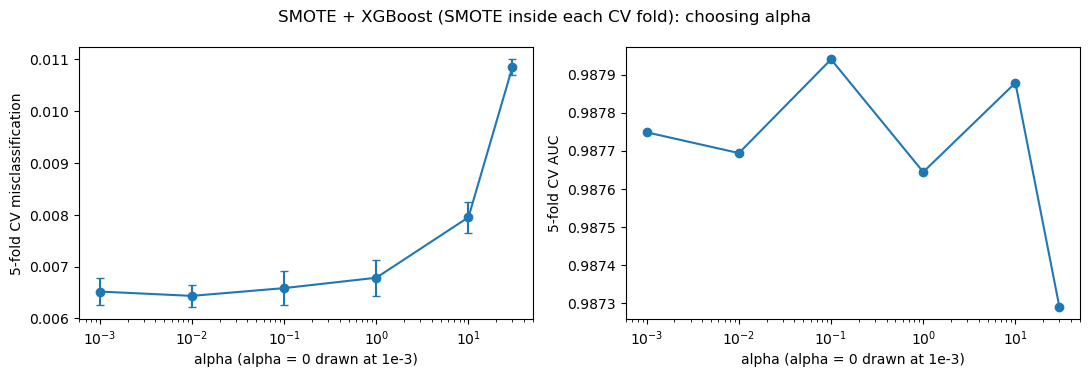

,CV error,CV error SE,CV AUC,seconds
alpha,,,,
0.00,0.00652,0.00027,0.98775,235.87713
0.01,0.00643,0.00021,0.98769,55.48526
0.10,0.00658,0.00032,0.98794,56.73649
1.00,0.00678,0.00035,0.98764,62.46934
10.00,0.00795,0.00030,0.98788,50.52439
30.00,0.01085,0.00015,0.98729,42.72641


In [18]:
def make_smote_xgb(alpha):
    return ImbPipeline([("smote", SMOTE(k_neighbors=5, random_state=SEED)), ("xgb", make_xgb(alpha))])


cv_smote = cv_over_alpha(make_smote_xgb, X_train, y_train)
plot_cv(cv_smote, "SMOTE + XGBoost (SMOTE inside each CV fold): choosing alpha")
cv_smote.round(5)

alpha chosen by 5-fold CV: 0.01
SMOTE on the full training set: (60000, 170) -> (118000, 170), class counts [59000, 59000]  (0.4 s)


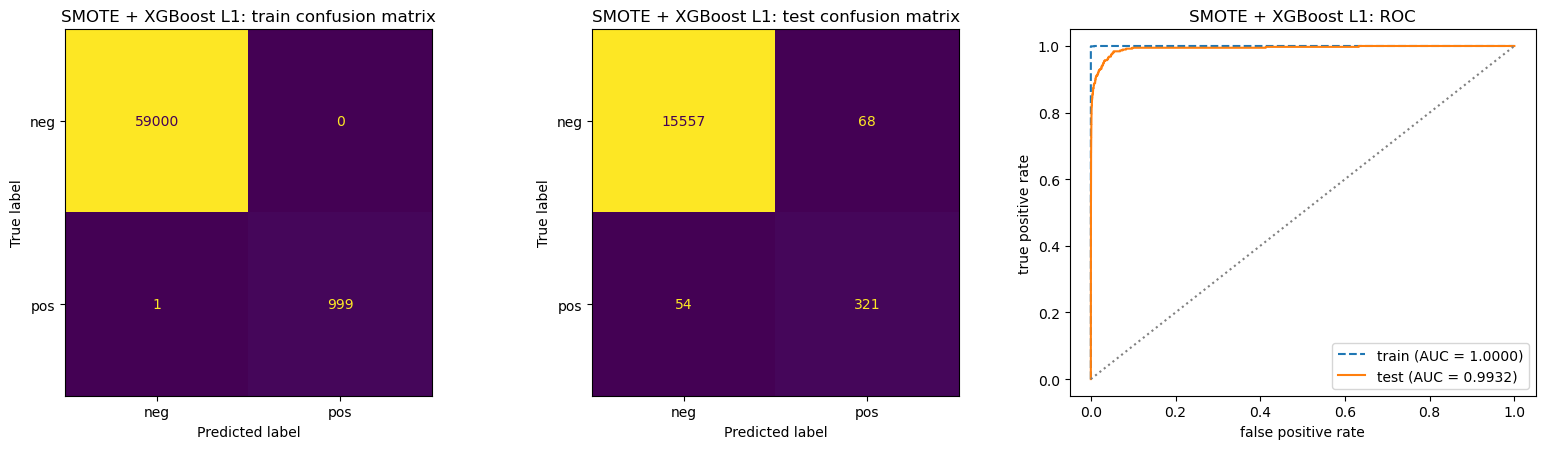

      misclassification     AUC       TN    FP    FN     TP     cost
train           0.00002 0.99999  59000.0   0.0   1.0  999.0    500.0
test            0.00762 0.99316  15557.0  68.0  54.0  321.0  27680.0

5-fold CV error estimate: 0.00643   test error: 0.00762


In [19]:
alpha_smote = cv_smote["CV error"].idxmin()
print("alpha chosen by 5-fold CV:", alpha_smote)

t0 = time.time()
X_sm, y_sm = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(X_train, y_train)
print("SMOTE on the full training set: %s -> %s, class counts %s  (%.1f s)"
      % (X_train.shape, X_sm.shape, np.bincount(y_sm).tolist(), time.time() - t0))

xgb_sm = make_xgb(alpha_smote).fit(X_sm, y_sm)
smote_table = evaluate("SMOTE + XGBoost L1", xgb_sm, {"OOB / CV error": cv_smote.loc[alpha_smote, "CV error"]})
print("\n5-fold CV error estimate: %.5f   test error: %.5f" % (cv_smote.loc[alpha_smote, "CV error"], smote_table.loc["test", "misclassification"]))

The training-set rows above are the **original** 60,000 training points (not the SMOTE-augmented set). For comparison, the *wrong* way of cross-validation (SMOTE on the whole training set first, then 5-fold CV on the augmented data) with the same α:

In [20]:
wrong = cross_validate(make_xgb(alpha_smote), X_sm, y_sm, cv=skf, scoring=["accuracy", "roc_auc"], n_jobs=1)
print("wrong way  (SMOTE before CV): CV error = %.5f, CV AUC = %.5f" % (1 - wrong["test_accuracy"].mean(), wrong["test_roc_auc"].mean()))
print("right way  (SMOTE inside CV): CV error = %.5f, CV AUC = %.5f" % (cv_smote.loc[alpha_smote, "CV error"], cv_smote.loc[alpha_smote, "CV AUC"]))
print("test error of the final SMOTE + XGBoost model: %.5f" % smote_table.loc["test", "misclassification"])

wrong way  (SMOTE before CV): CV error = 0.00222, CV AUC = 0.99996
right way  (SMOTE inside CV): CV error = 0.00643, CV AUC = 0.98769
test error of the final SMOTE + XGBoost model: 0.00762


**Discussion: SMOTE vs. no compensation, and the right vs. wrong way of CV.**

- **Wrong vs. right CV.** When SMOTE is applied before cross-validation, the CV error is 0.22% with AUC 0.99996: the validation folds contain synthetic positive points that are interpolations of points in the training folds, so they are very easy to classify. With SMOTE inside the folds, the CV error is 0.643% (AUC 0.988), which is close to the real test error of 0.762%. Only the right way gives a usable estimate.
- **With vs. without SMOTE.** CV picks a small α in both cases (0.01 with SMOTE, 1 without). With SMOTE, the test misclassification rate is slightly higher (0.762% vs. 0.656%) and the AUC slightly lower (0.9932 vs. 0.9957). However, the errors are distributed differently. The number of missed failures falls from 87 to 54 (recall 85.6% vs. 76.8%), and the number of false alarms rises from 18 to 68. Under the challenge cost, the SMOTE model is clearly better (27,680 vs. 43,680).
- SMOTE moves the model towards the minority class like the balanced random forest, but much less strongly, because XGBoost still fits the synthetic points closely. Even with SMOTE the training set is fitted almost perfectly, and the threshold-free AUC does not improve. SMOTE helps through a better operating point for the rare class, not through a better ranking.

### Summary of Problem 1

In [21]:
summary = pd.DataFrame(results).T[["OOB / CV error", "train error", "test error", "train AUC", "test AUC", "test FP", "test FN", "test cost"]]
summary.style.format({"OOB / CV error": "{:.5f}", "train error": "{:.5f}", "test error": "{:.5f}",
                      "train AUC": "{:.5f}", "test AUC": "{:.5f}", "test FP": "{:.0f}", "test FN": "{:.0f}", "test cost": "{:,.0f}"})

,OOB / CV error,train error,test error,train AUC,test AUC,test FP,test FN,test cost
RF (uncompensated),0.00575,0.00000,0.00762,1.00000,0.99445,17,105,"52,670"
RF (class weights),0.00767,0.00000,0.01069,1.00000,0.99308,14,157,"78,640"
Balanced RF (down-sampling),0.05063,0.05460,0.05181,0.99759,0.99240,823,6,"11,230"
XGBoost L1 (uncompensated),0.00568,0.00002,0.00656,0.99999,0.99570,18,87,"43,680"
SMOTE + XGBoost L1,0.00643,0.00002,0.00762,0.99999,0.99316,68,54,"27,680"


**Overall.** All five models rank the trucks almost equally well (test AUC 0.992–0.996), with plain XGBoost the best on misclassification rate and AUC. The internal estimates (OOB for the forests, 5-fold CV for XGBoost, and SMOTE inside the folds) are all close to the test errors, and slightly optimistic only because the test set has a larger share of positives. The wrong way of cross-validating with SMOTE is far too optimistic. Compensating for the class imbalance (balanced RF, SMOTE) increases the misclassification rate a little but greatly reduces the number of missed APS failures, and therefore the cost; class weights on fully grown trees have almost no effect.

## 2. ISLR 6.6.3

The lasso-type problem: minimize $\sum_{i=1}^n \bigl(y_i - \beta_0 - \sum_{j=1}^p \beta_j x_{ij}\bigr)^2$ subject to $\sum_{j=1}^p |\beta_j| \le s$, as $s$ increases from 0.

At $s = 0$ all slopes are zero (the null model, only $\hat\beta_0 = \bar y$). As $s$ grows, the constraint is relaxed, and for $s$ large enough it is not active and the solution is the least-squares fit. So increasing $s$ means increasing the flexibility of the model.

**(a) Training RSS — (iv) steadily decreases.** The feasible set $\{\beta : \sum|\beta_j| \le s\}$ grows with $s$, so the minimum of the training RSS over it can only go down (or stay constant once least squares is reached).

**(b) Test RSS — (ii) decreases initially, and then eventually starts increasing in a U shape.** At first, freeing the coefficients removes a lot of bias at a small cost in variance, so the test RSS falls. When $s$ becomes large, the model starts to fit noise in the training data, the extra variance is larger than the bias that is removed, and the test RSS rises again towards that of least squares.

**(c) Variance — (iii) steadily increases.** At $s = 0$ the fit does not depend on the training $x$'s at all (variance essentially 0). Larger $s$ lets the coefficients follow the particular training sample more closely, so the variance grows.

**(d) (Squared) bias — (iv) steadily decreases.** The null model has the largest bias. As $s$ increases, the coefficients are shrunk less and the model can get closer to the true relation, so the bias decreases (down to the bias of least squares).

**(e) Irreducible error — (v) remains constant.** $\text{Var}(\varepsilon)$ is a property of the data-generating process, not of the model, so it does not depend on $s$.

## 3. ISLR 6.6.5

Setting: $n = 2$, $p = 2$, $x_{11} = x_{12}$, $x_{21} = x_{22}$, $y_1 + y_2 = 0$, $x_{11} + x_{21} = 0$, $x_{12} + x_{22} = 0$, so that $\hat\beta_0 = 0$. Write $a = x_{11} = x_{12}$; then $x_{21} = x_{22} = -a$ and $y_2 = -y_1$ (assume $a \ne 0$).

**(a) Ridge optimization problem.**
$$
\min_{\beta_1,\beta_2}\; \bigl(y_1 - \beta_1 x_{11} - \beta_2 x_{12}\bigr)^2 + \bigl(y_2 - \beta_1 x_{21} - \beta_2 x_{22}\bigr)^2 + \lambda\bigl(\beta_1^2 + \beta_2^2\bigr).
$$
With the setting above, both residuals are $\pm\bigl(y_1 - a(\beta_1+\beta_2)\bigr)$, so the objective is
$$
R(\beta_1,\beta_2) = 2\bigl(y_1 - a(\beta_1 + \beta_2)\bigr)^2 + \lambda\bigl(\beta_1^2 + \beta_2^2\bigr).
$$

**(b) The ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$.** Set the partial derivatives to zero:
$$
\frac{\partial R}{\partial \beta_1} = -4a\bigl(y_1 - a(\beta_1+\beta_2)\bigr) + 2\lambda\beta_1 = 0, \qquad
\frac{\partial R}{\partial \beta_2} = -4a\bigl(y_1 - a(\beta_1+\beta_2)\bigr) + 2\lambda\beta_2 = 0.
$$
The first terms are identical, so subtracting the equations gives $2\lambda(\beta_1 - \beta_2) = 0$, i.e. $\hat\beta_1 = \hat\beta_2$ for $\lambda > 0$. ($R$ is strictly convex for $\lambda > 0$, so this stationary point is the unique minimizer.) Plugging $\beta_1 = \beta_2 = \beta$ in gives $-4a(y_1 - 2a\beta) + 2\lambda\beta = 0$, so
$$
\hat\beta_1 = \hat\beta_2 = \frac{2 a y_1}{4a^2 + \lambda}.
$$

**(c) Lasso optimization problem.**
$$
\min_{\beta_1,\beta_2}\; \bigl(y_1 - \beta_1 x_{11} - \beta_2 x_{12}\bigr)^2 + \bigl(y_2 - \beta_1 x_{21} - \beta_2 x_{22}\bigr)^2 + \lambda\bigl(|\beta_1| + |\beta_2|\bigr)
= 2\bigl(y_1 - a(\beta_1 + \beta_2)\bigr)^2 + \lambda\bigl(|\beta_1| + |\beta_2|\bigr).
$$

**(d) The lasso coefficients are not unique.** The RSS depends on $(\beta_1, \beta_2)$ only through $t = \beta_1 + \beta_2$, and $|\beta_1| + |\beta_2| \ge |t|$ with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one is 0). So the problem reduces to the one-dimensional lasso $\min_t 2(y_1 - a t)^2 + \lambda |t|$, whose solution is the soft-thresholded value
$$
\hat t = \operatorname{sign}\!\Bigl(\frac{y_1}{a}\Bigr)\,\max\Bigl(\Bigl|\frac{y_1}{a}\Bigr| - \frac{\lambda}{4a^2},\; 0\Bigr),
$$
and **every** pair with $\hat\beta_1 + \hat\beta_2 = \hat t$ and $\hat\beta_1 \hat\beta_2 \ge 0$ attains the minimum. For $\hat t \ne 0$ this is the whole line segment from $(\hat t, 0)$ to $(0, \hat t)$, e.g. for $\hat t > 0$:
$$
\{(\beta_1, \beta_2) : \beta_1 + \beta_2 = \hat t,\ \beta_1 \ge 0,\ \beta_2 \ge 0\}.
$$
Geometrically, the RSS contours are the lines $\beta_1 + \beta_2 = \text{const}$, which are parallel to the edge $\beta_1 + \beta_2 = s$ of the lasso diamond $|\beta_1| + |\beta_2| \le s$; the smallest contour touching the diamond touches it along a whole edge, not at a single corner.

## 4. ISLR 8.4.5

Ten bootstrap estimates of $P(\text{Class is Red} \mid X)$: 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

- **Majority vote:** 6 of the 10 estimates are above 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), so 6 trees vote Red and 4 vote Green → the final classification is **Red**.
- **Average probability:** $\bar p = (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 4.5/10 = 0.45 < 0.5$ → the final classification is **Green**.

The two approaches disagree because the four "Green" trees are very confident (probabilities 0.1–0.2), while the six "Red" trees are only mildly confident (0.55–0.75).

## 5. ISLR 9.7.3

Seven observations in $p = 2$ dimensions:

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a)** The sketch is the first panel below.

**(b) Optimal separating hyperplane.** The closest pairs across the classes are Red (2, 2) and Blue (2, 1), and Red (4, 4) and Blue (4, 3). In both pairs the Red point lies on the line $X_1 - X_2 = 0$ and the Blue point on $X_1 - X_2 = 1$, and all Red points satisfy $X_1 - X_2 \le 0$, all Blue points $X_1 - X_2 \ge 1$. The maximal margin hyperplane lies halfway between these two parallel lines:
$$
X_1 - X_2 - 0.5 = 0 \quad\Longleftrightarrow\quad X_2 = X_1 - 0.5,
$$
the line through (2, 1.5) and (4, 3.5).

**(c) Classification rule.** Classify to Red if $0.5 - X_1 + X_2 > 0$, and to Blue otherwise, i.e. $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$. (Check: Red (1, 4) gives $3.5 > 0$, Blue (4, 1) gives $-2.5 < 0$.)

**(d) Margin.** The distance from a support vector to the hyperplane is $M = \dfrac{|2 - 2 - 0.5|}{\sqrt{1^2 + 1^2}} = \dfrac{0.5}{\sqrt 2} = \dfrac{\sqrt 2}{4} \approx 0.354$ on each side (the gap between the two margin lines $X_1 - X_2 = 0$ and $X_1 - X_2 = 1$ is $1/\sqrt2 \approx 0.707$). The margins are the dashed lines in the second panel.

**(e) Support vectors:** Red (2, 2), Red (4, 4), Blue (2, 1) and Blue (4, 3) (circled in the second panel).

**(f)** The seventh observation, Blue (4, 1), has $X_1 - X_2 = 3$, so it lies far from the margin ($2.5/\sqrt 2 \approx 1.77$ from the hyperplane) and is not a support vector. The maximal margin hyperplane depends only on the support vectors, so a slight movement of (4, 1) that keeps it outside the margin does not change the hyperplane.

**(g) A separating hyperplane that is not optimal:** $X_1 - X_2 - 0.2 = 0$ (i.e. $X_2 = X_1 - 0.2$). It still separates the classes ($X_1 - X_2 \le 0 < 0.2$ for Red, $\ge 1 > 0.2$ for Blue), but its distance to the nearest Red point is only $0.2/\sqrt2 \approx 0.14$, smaller than the maximal margin. Third panel.

**(h) An additional observation that makes the classes non-separable:** a **Red** point at (4, 2). It lies between the Blue points (4, 1) and (4, 3) and has $X_1 - X_2 = 2$, on the Blue side; there is no line with all Red points on one side and all Blue points on the other, because the Red point (4, 2) lies on the segment joining Blue (4, 1) and Blue (4, 3), so it is in the convex hull of the Blue class. Fourth panel.

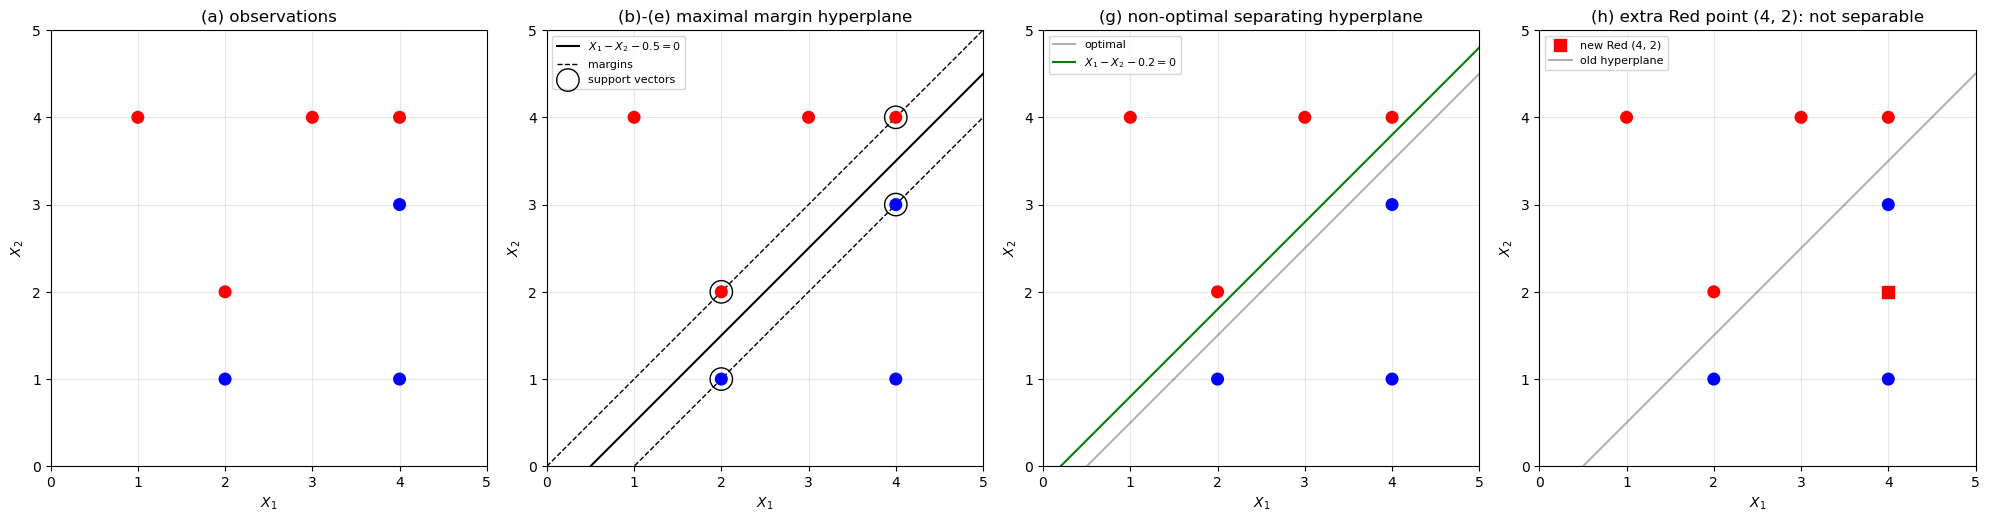

In [22]:
X93 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
c93 = np.array(["red"] * 4 + ["blue"] * 3)
xs = np.linspace(0, 5, 2)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
titles = ["(a) observations", "(b)-(e) maximal margin hyperplane", "(g) non-optimal separating hyperplane",
          "(h) extra Red point (4, 2): not separable"]
for ax, t in zip(axes, titles):
    ax.scatter(X93[:, 0], X93[:, 1], c=c93, s=70, zorder=3)
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_aspect("equal")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_title(t)
    ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(xs, xs - 0.5, "k-", label="$X_1 - X_2 - 0.5 = 0$")
ax.plot(xs, xs, "k--", lw=1, label="margins")
ax.plot(xs, xs - 1, "k--", lw=1)
sv = X93[[1, 2, 4, 5]]
ax.scatter(sv[:, 0], sv[:, 1], s=260, facecolors="none", edgecolors="k", label="support vectors", zorder=4)
ax.legend(loc="upper left", fontsize=8)

ax = axes[2]
ax.plot(xs, xs - 0.5, "k-", alpha=0.3, label="optimal")
ax.plot(xs, xs - 0.2, "g-", label="$X_1 - X_2 - 0.2 = 0$")
ax.legend(loc="upper left", fontsize=8)

ax = axes[3]
ax.scatter([4], [2], c="red", s=70, marker="s", zorder=3, label="new Red (4, 2)")
ax.plot(xs, xs - 0.5, "k-", alpha=0.3, label="old hyperplane")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()